# 34 · Filters

**Question.** Which filter should prepare the state: imaginary time (QITE) or the minimax edge filter?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p4_filters", "p5_filters")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p4_filters: 35 records, 35 ok
p5_filters: 88 records, 88 ok


In [2]:
from IPython.display import Markdown, display

forms = {"standard": results.rows("p4_filters"), "descriptor": results.rows("p5_filters")}
forms = {form: [r for r in rows if r["status"] == "ok"] for form, rows in forms.items()}
columns = {k for rows in forms.values() for k in rows[0]}
prefixes = sorted(
    {k.split("_")[0] for k in columns if k.endswith("_qite_degree")}, key=lambda p: int(p[1:])
)


def ratios(rows, prefix, kind):
    """Return QITE's degree over the minimax filter's, certified or measured, where both exist.

    Certified, each is the least degree the same worst-case bound certifies (QITE over its τ).
    """
    q = f"{prefix}_qite_{'worst' if kind == 'certified' else kind}"
    m = f"{prefix}_minimax_{kind}"
    return [r[q] / r[m] for r in rows if isinstance(r[q], int) and isinstance(r[m], int)]


lines = []
for form, rows in forms.items():
    trusted = [r for r in rows if r["trusted"]]
    for prefix in prefixes:
        certified, measured = ratios(trusted, prefix, "certified"), ratios(rows, prefix, "degree")
        lines.append(
            f"- The {form} form at ε = 1e-{prefix[1:]}: QITE needs {min(certified):.2f} to "
            f"{max(certified):.2f} times the minimax filter's certified degree on trusted records, "
            f"and {min(measured):.2f} to {max(measured):.2f} times its measured degree on every "
            f"record (QITE lower in {sum(x < 1.0 for x in measured)} of {len(measured)})."
        )
    misses = [r for r in rows if r[f"{prefixes[1]}_production_reaches"] is False]
    if misses:
        lines.append(
            f"- The {form} form's production rule (QITE's a priori τ) misses ε = 1e-"
            f"{prefixes[1][1:]} in {len(misses)} of {len(rows)} records, all with λ₀/Δ ≥ "
            f"{min(r['offset'] for r in misses):.2f}, {sum(r['trusted'] for r in misses)} trusted."
        )
display(Markdown("\n".join(lines)))

- The standard form at ε = 1e-4: QITE needs 1.67 to 1.76 times the minimax filter's certified degree on trusted records, and 0.77 to 2.99 times its measured degree on every record (QITE lower in 9 of 33).
- The standard form at ε = 1e-6: QITE needs 1.75 to 1.81 times the minimax filter's certified degree on trusted records, and 1.19 to 2.50 times its measured degree on every record (QITE lower in 0 of 32).
- The standard form at ε = 1e-8: QITE needs 1.80 to 1.84 times the minimax filter's certified degree on trusted records, and 1.34 to 2.53 times its measured degree on every record (QITE lower in 0 of 31).
- The standard form's production rule (QITE's a priori τ) misses ε = 1e-6 in 9 of 35 records, all with λ₀/Δ ≥ 0.76, 0 trusted.
- The descriptor form at ε = 1e-4: QITE needs 1.55 to 1.81 times the minimax filter's certified degree on trusted records, and 0.23 to 2.37 times its measured degree on every record (QITE lower in 12 of 87).
- The descriptor form at ε = 1e-6: QITE needs 1.73 to 1.84 times the minimax filter's certified degree on trusted records, and 0.73 to 2.65 times its measured degree on every record (QITE lower in 2 of 86).
- The descriptor form at ε = 1e-8: QITE needs 1.73 to 1.86 times the minimax filter's certified degree on trusted records, and 1.02 to 2.58 times its measured degree on every record (QITE lower in 0 of 85).
- The descriptor form's production rule (QITE's a priori τ) misses ε = 1e-6 in 9 of 88 records, all with λ₀/Δ ≥ 0.68, 0 trusted.

Left, each record where the filter study's map places it: the gap on the scale of H′ against the
ground state's height above the spectrum's edge, in gaps. Right, QITE's measured degree over the
minimax filter's at ε = 1e-6, by that height; above one the minimax filter is cheaper.

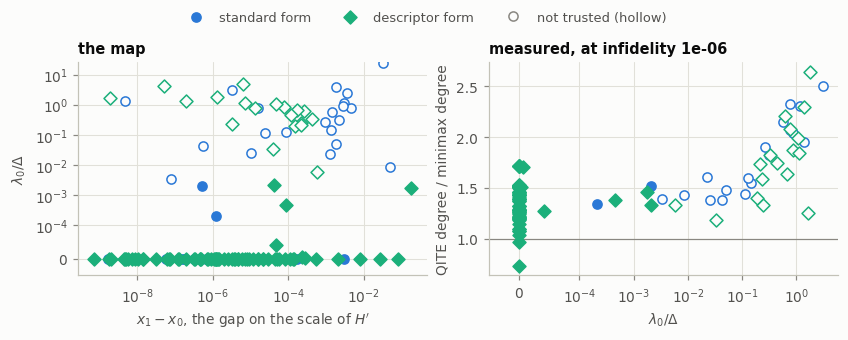

In [3]:
plotting.filter_map(forms);

**What this does not show.** The comparison is on the exact emulation (T2), from the geometric
initial state. The other campaigns prepare with the minimax filter; QITE stays for the paper's
reproduction and for comparison.